# Data preparation for model comparison

Target: `final_grade_pct` (regression). Predictors are grouped as continuous, discrete, or categorical.

In [24]:
import numpy as np
import pandas as pd

df = pd.read_csv('student_grade_ses_dataset.csv')
print(df.shape)

(12025, 29)


## Clean rows

Duplicates: 25 rows are exact copies, so they are removed.

Missing values: 9 columns have gaps, and 3,215 of 12,000 rows (27%) have at least one. Missingness looks random, since the final grade is about the same whether or not a value is missing. We drop those rows (complete-case analysis).

In [25]:
n_raw = len(df)
df = df.drop_duplicates().reset_index(drop=True)
n_unique = len(df)
df = df.dropna().reset_index(drop=True)
print(f'{n_raw} rows -> {n_unique} after removing duplicates -> {len(df)} after dropping rows with missing values')

12025 rows -> 12000 after removing duplicates -> 8785 after dropping rows with missing values


## Target and predictors

`grade_class` and `at_risk_flag` are excluded because both are computed from the target. `student_id` becomes the row index, and `survey_date` is excluded because all survey dates fall in March to May 2025.

In [26]:
TARGET_COL = 'final_grade_pct'

# Heavily skewed income, so log-transformed
df['log_income'] = np.log(df.pop('annual_family_income_inr'))

CONTINUOUS_COLS = ['distance_to_school_km', 'study_hours_per_week', 'attendance_rate_pct',
                   'previous_year_grade_pct', 'log_income']

# Integer-coded, including 0/1 flags and the 1-5 parental involvement score
DISCRETE_COLS = ['age', 'grade_level', 'family_size', 'num_siblings', 'single_parent_household',
                 'has_internet_access', 'has_computer_or_laptop', 'extra_tutoring',
                 'parental_involvement_score']

# Text labels
CATEGORICAL_COLS = ['academic_year', 'gender', 'school_type', 'residence_type', 'family_income_bracket',
                    'father_education_level', 'mother_education_level', 'father_occupation',
                    'mother_occupation', 'scholarship_status']

NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

In [27]:
# student_id is unique after de-duplication, so it can serve as the row index
df = df.set_index('student_id')
assert df.index.is_unique

X = df[PREDICTOR_COLS]
Y = df[TARGET_COL]
print('X:', X.shape, ' Y:', Y.shape)

X: (8785, 24)  Y: (8785,)


## One-hot encoding

Each categorical predictor becomes 0/1 columns, one per level. The first level of each variable is dropped as the reference, which avoids perfect collinearity with the intercept in linear models. Tree models don't need this, but using the same encoding keeps all models comparable. The mapping from labels to columns is fixed by the data and learns nothing from the target, so it doesn't leak information. `X` is left unchanged, and the encoded version is stored as `X_encoded`.

In [28]:
X_encoded = pd.get_dummies(X, columns=CATEGORICAL_COLS, drop_first=True, dtype=float)
assert X_encoded.notna().all().all()
print('X_encoded:', X_encoded.shape)

X_encoded: (8785, 54)


## Train/test split

85% of rows go to training and 15% to test. Stratifying on `grade_class` keeps the rare F and A grades in both sets. The test set is set aside and used only once, at the end.

In [29]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.15
SEED = 42

X_train, X_test, Y_train, Y_test = train_test_split(
    X_encoded, Y, test_size=TEST_SIZE, stratify=df['grade_class'], random_state=SEED)

print('train:', X_train.shape, ' test:', X_test.shape)
print('test grade_class counts:', df.loc[X_test.index, 'grade_class'].value_counts().to_dict())

train: (7467, 54)  test: (1318, 54)
test grade_class counts: {'C': 680, 'D': 301, 'B': 290, 'F': 24, 'A': 23}


## Predictor selection (Lasso)

The selection uses one Lasso step on the training rows only. Numeric predictors are standardised inside each CV fold, and the penalty is chosen by 10-fold CV with the one-standard-error rule. A predictor is kept if any of its encoded columns has a non-zero coefficient. The test set is not used here.

In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

N_SPLITS = 10


def source_variable(col):
    # Maps a one-hot column back to its raw predictor name
    for raw in PREDICTOR_COLS:
        if col == raw or col.startswith(raw + '_'):
            return raw
    return col


ALPHA_GRID = np.logspace(-4, 1, 60)
ALL_COLS = list(X_train.columns)


def make_pipe(cols):
    # Continuous and discrete columns (including 0/1 flags) are scaled. One-hot dummy columns pass through unchanged.
    scale_cols = [c for c in cols if source_variable(c) in NUMERIC_COLS]
    scaling = ColumnTransformer([('scale', StandardScaler(), scale_cols)],
                                remainder='passthrough', verbose_feature_names_out=False)
    return make_pipeline(scaling.set_output(transform='pandas'), Lasso(max_iter=20000))


def one_se_alpha(search):
    # Largest alpha whose CV error is within one standard error of the best
    mean_rmse = -search.cv_results_['mean_test_score']
    se = search.cv_results_['std_test_score'] / np.sqrt(N_SPLITS)
    best = np.argmin(mean_rmse)
    return ALPHA_GRID[mean_rmse <= mean_rmse[best] + se[best]].max()


folds = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_train))
search = GridSearchCV(make_pipe(ALL_COLS), {'lasso__alpha': ALPHA_GRID}, cv=folds,
                      scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, Y_train)
ALPHA_1SE = one_se_alpha(search)
print(f'CV-selected alpha: {search.best_params_["lasso__alpha"]:.4f}  CV RMSE: {-search.best_score_:.3f}')
print(f'alpha at 1-SE: {ALPHA_1SE:.4f}')

lasso_fit = make_pipe(ALL_COLS).set_params(lasso__alpha=ALPHA_1SE).fit(X_train, Y_train)
lasso_coef = pd.Series(lasso_fit[-1].coef_, index=lasso_fit[:-1].get_feature_names_out())
kept_levels = lasso_coef[lasso_coef != 0].index
SELECTED_PREDICTORS = [p for p in PREDICTOR_COLS if p in set(kept_levels.map(source_variable))]
DROPPED_PREDICTORS = [p for p in PREDICTOR_COLS if p not in SELECTED_PREDICTORS]
FINAL_COLS = [c for c in ALL_COLS if source_variable(c) in SELECTED_PREDICTORS]

X_train_final = X_train[FINAL_COLS]
X_test_final = X_test[FINAL_COLS]
print(f'kept {len(SELECTED_PREDICTORS)} of {len(PREDICTOR_COLS)} predictors ({len(FINAL_COLS)} encoded columns)')
print('dropped:', DROPPED_PREDICTORS)
print('zeroed levels:', lasso_coef[lasso_coef == 0].index.tolist())

CV-selected alpha: 0.0160  CV RMSE: 9.596
alpha at 1-SE: 0.2454
kept 10 of 24 predictors (11 encoded columns)
dropped: ['distance_to_school_km', 'age', 'grade_level', 'num_siblings', 'parental_involvement_score', 'academic_year', 'gender', 'school_type', 'residence_type', 'family_income_bracket', 'father_education_level', 'mother_education_level', 'father_occupation', 'mother_occupation']
zeroed levels: ['distance_to_school_km', 'age', 'grade_level', 'num_siblings', 'parental_involvement_score', 'academic_year_2022-2023', 'academic_year_2023-2024', 'academic_year_2024-2025', 'gender_Male', 'gender_Other', 'school_type_Government-Aided', 'school_type_Private-Unaided', 'residence_type_Semi-Urban', 'residence_type_Urban', 'family_income_bracket_Low', 'family_income_bracket_Lower-Middle', 'family_income_bracket_Middle', 'family_income_bracket_Upper-Middle', 'father_education_level_Doctorate', 'father_education_level_Higher Secondary', "father_education_level_Master's Degree", 'father_educa

## Nested cross-validation (honest estimate)

The Lasso selection step is repeated inside each of 10 outer folds, using only that fold's training rows. The selected predictors are refitted with OLS and scored on the held-out outer fold. For comparison, OLS on all predictors is scored on the same folds. Selection runs on the full training set before the comparison, so this section checks whether the selection itself helps. The test set is not used here.

In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error


def select_predictors(X_tr, Y_tr):
    cols = list(X_tr.columns)
    inner = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_tr))
    search = GridSearchCV(make_pipe(cols), {'lasso__alpha': ALPHA_GRID}, cv=inner,
                          scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_tr, Y_tr)
    alpha = one_se_alpha(search)
    fitted = make_pipe(cols).set_params(lasso__alpha=alpha).fit(X_tr, Y_tr)
    coef = pd.Series(fitted[-1].coef_, index=fitted[:-1].get_feature_names_out())
    kept = set(coef[coef != 0].index.map(source_variable))
    return [c for c in cols if source_variable(c) in kept]


outer = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_train))
rows, kept_counts = [], {}
for k, (tr_i, va_i) in enumerate(outer):
    X_tr, X_va = X_train.iloc[tr_i], X_train.iloc[va_i]
    Y_tr, Y_va = Y_train.iloc[tr_i], Y_train.iloc[va_i]

    cols = select_predictors(X_tr, Y_tr)
    selected = LinearRegression().fit(X_tr[cols], Y_tr)
    rmse_sel = root_mean_squared_error(Y_va, selected.predict(X_va[cols]))

    everything = LinearRegression().fit(X_tr, Y_tr)
    rmse_all = root_mean_squared_error(Y_va, everything.predict(X_va))

    preds = sorted(set(source_variable(c) for c in cols))
    rows.append({'outer_fold': k, 'n_predictors': len(preds),
                 'rmse_selected_ols': rmse_sel, 'rmse_all_ols': rmse_all})
    for raw in preds:
        kept_counts[raw] = kept_counts.get(raw, 0) + 1

nested = pd.DataFrame(rows)
print(nested.round(3).to_string(index=False))
print(f"mean outer RMSE: OLS on selected {nested['rmse_selected_ols'].mean():.3f}, OLS on all predictors {nested['rmse_all_ols'].mean():.3f}")
print('outer folds (of 10) in which each predictor was kept:')
print(pd.Series(kept_counts).sort_values(ascending=False).to_string())


 outer_fold  n_predictors  rmse_selected_ols  rmse_all_ols
          0             7              9.751         9.726
          1             7              9.940         9.753
          2            12              9.761         9.770
          3             9             10.197        10.152
          4             6             10.030         9.822
          5            10              8.902         8.923
          6             7              9.653         9.473
          7             6             10.200         9.973
          8             7              8.890         8.817
          9            12              9.635         9.602
mean outer RMSE: OLS on selected 9.696, OLS on all predictors 9.601
outer folds (of 10) in which each predictor was kept:
attendance_rate_pct        10
has_computer_or_laptop     10
has_internet_access        10
log_income                 10
previous_year_grade_pct    10
study_hours_per_week       10
extra_tutoring              8
family_size        

## Model comparison: shared setup

Every model is evaluated on the same 10 outer folds of the training set, using the predictors kept by the Lasso selection step. The helper below fits each model on the outer training folds, records the validation RMSE, then refits on all training rows and scores once on the test set. The mean-only baseline is run here as a reference.

In [32]:
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

MODEL_COLS = list(X_train_final.columns)
RIDGE_GRID = np.logspace(-3, 3, 50)
inner_cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
outer_folds = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_train_final))


def run_group(factories):
    # factories maps a model name to a function that returns a fresh, unfitted model
    cv_fold_rmse = {name: [] for name in factories}
    for fold, (train_idx, valid_idx) in enumerate(outer_folds, start=1):
        X_tr, X_valid = X_train_final.iloc[train_idx], X_train_final.iloc[valid_idx]
        Y_tr, Y_valid = Y_train.iloc[train_idx], Y_train.iloc[valid_idx]
        for name, make in factories.items():
            model = make().fit(X_tr, Y_tr)
            cv_fold_rmse[name].append(root_mean_squared_error(Y_valid, model.predict(X_valid)))
        print(f'Finished outer fold {fold}/{len(outer_folds)}')

    fitted, rows = {}, []
    for name, make in factories.items():
        model = make().fit(X_train_final, Y_train)
        if isinstance(model, GridSearchCV):
            print(f'{name} selected on all training rows: {model.best_params_}')
            fitted[name] = model.best_estimator_
        else:
            fitted[name] = model
        rows.append({
            'model': name,
            'cv_rmse': np.mean(cv_fold_rmse[name]),
            'cv_rmse_sd': np.std(cv_fold_rmse[name], ddof=1),
            'test_rmse': root_mean_squared_error(Y_test, model.predict(X_test_final)),
        })
    table = pd.DataFrame(rows).set_index('model')
    print(table.round(3).to_string())
    return {'cv_fold_rmse': cv_fold_rmse, 'fitted': fitted, 'table': table}


def scaled_model(cols, estimator):
    scale_cols = [c for c in cols if source_variable(c) in NUMERIC_COLS]
    scaling = ColumnTransformer([('scale', StandardScaler(), scale_cols)],
                                remainder='passthrough', verbose_feature_names_out=False)
    return make_pipeline(scaling.set_output(transform='pandas'), estimator)


baseline_results = run_group({'Mean only (baseline)': lambda: DummyRegressor(strategy='mean')})

Finished outer fold 1/10
Finished outer fold 2/10
Finished outer fold 3/10
Finished outer fold 4/10
Finished outer fold 5/10
Finished outer fold 6/10
Finished outer fold 7/10
Finished outer fold 8/10
Finished outer fold 9/10
Finished outer fold 10/10
                      cv_rmse  cv_rmse_sd  test_rmse
model                                               
Mean only (baseline)   11.623       0.372     11.834


### Linear models (OLS, Ridge, Lasso)

Ridge and Lasso are standardized inside each fold, and their penalties are chosen by the inner 10-fold CV. OLS uses the same scaling so the three share one pipeline shape.

Finished outer fold 1/10
Finished outer fold 2/10
Finished outer fold 3/10
Finished outer fold 4/10
Finished outer fold 5/10
Finished outer fold 6/10
Finished outer fold 7/10
Finished outer fold 8/10
Finished outer fold 9/10
Finished outer fold 10/10
Ridge selected on all training rows: {'ridge__alpha': np.float64(6.25055192527397)}
Lasso selected on all training rows: {'lasso__alpha': np.float64(0.0001)}
       cv_rmse  cv_rmse_sd  test_rmse
model                                
OLS      9.669       0.455      9.508
Ridge    9.669       0.455      9.508
Lasso    9.669       0.455      9.508


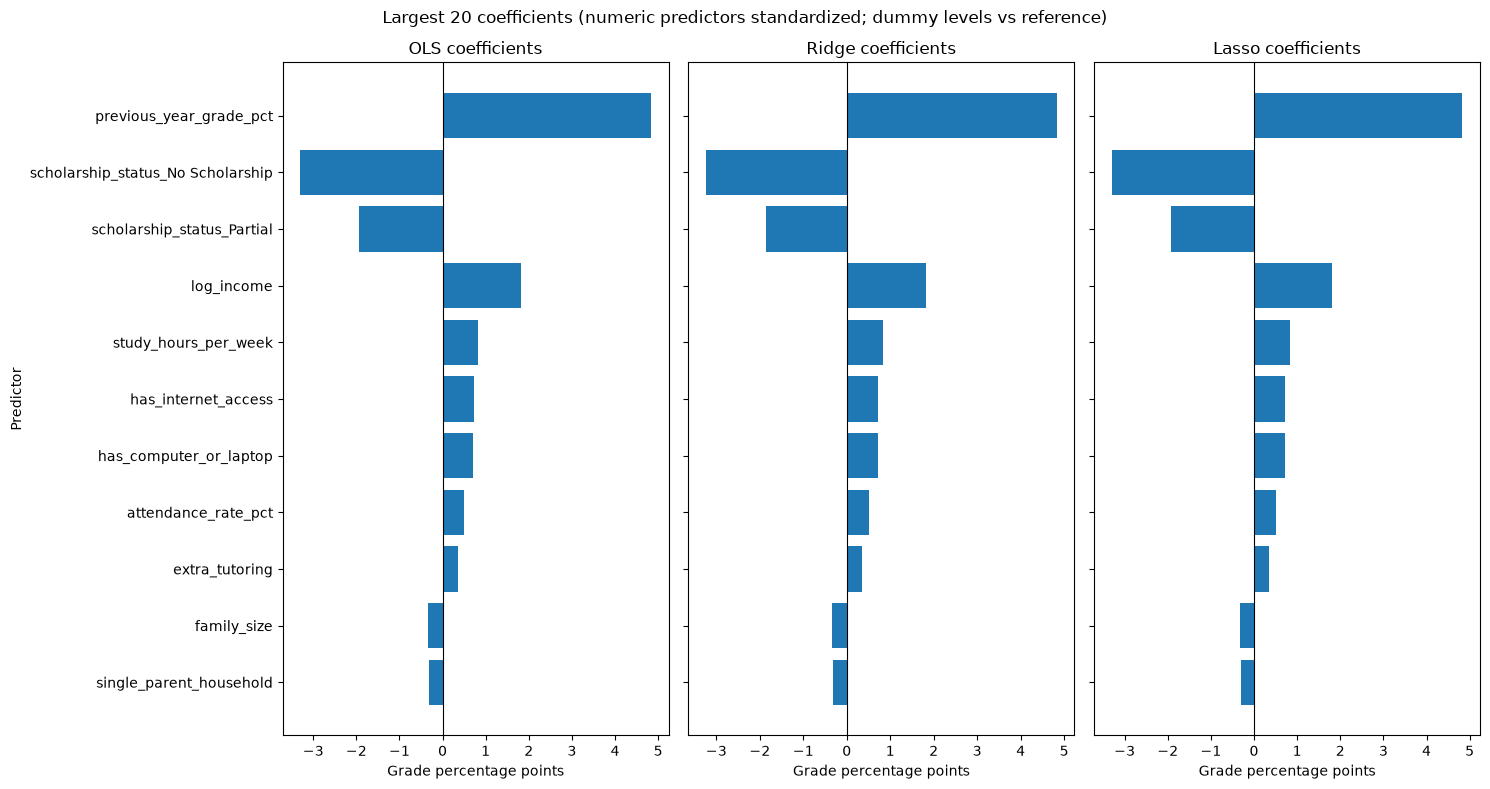

In [33]:
def tune_ridge():
    return GridSearchCV(scaled_model(MODEL_COLS, Ridge()), {'ridge__alpha': RIDGE_GRID},
                        cv=inner_cv, scoring='neg_root_mean_squared_error', n_jobs=-1)


def tune_lasso():
    return GridSearchCV(scaled_model(MODEL_COLS, Lasso(max_iter=20000)), {'lasso__alpha': ALPHA_GRID},
                        cv=inner_cv, scoring='neg_root_mean_squared_error', n_jobs=-1)


linear_results = run_group({
    'OLS': lambda: scaled_model(MODEL_COLS, LinearRegression()),
    'Ridge': tune_ridge,
    'Lasso': tune_lasso,
})

coef_series = {}
for name in ['OLS', 'Ridge', 'Lasso']:
    fitted = linear_results['fitted'][name]
    coef_series[name] = pd.Series(fitted[-1].coef_, index=fitted[:-1].get_feature_names_out())

largest = pd.concat(coef_series, axis=1).abs().max(axis=1)
feature_order = largest.nlargest(min(20, len(largest))).sort_values().index
fig, axes = plt.subplots(1, 3, figsize=(15, 8), sharey=True)
for ax, name in zip(axes, ['OLS', 'Ridge', 'Lasso']):
    ax.barh(feature_order, coef_series[name].loc[feature_order])
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'{name} coefficients')
    ax.set_xlabel('Grade percentage points')
axes[0].set_ylabel('Predictor')
fig.suptitle('Largest 20 coefficients (numeric predictors standardized; dummy levels vs reference)')
plt.tight_layout()
plt.show()

### Tree models (Decision Tree, Random Forest)

Trees are invariant to scaling, so they use the raw predictors. Each model tunes its complexity with the same inner 10-fold CV.

Finished outer fold 1/10
Finished outer fold 2/10
Finished outer fold 3/10
Finished outer fold 4/10
Finished outer fold 5/10
Finished outer fold 6/10
Finished outer fold 7/10
Finished outer fold 8/10
Finished outer fold 9/10
Finished outer fold 10/10
Decision Tree selected on all training rows: {'max_depth': 4, 'min_samples_leaf': 10}
Random Forest selected on all training rows: {'max_features': 0.6, 'min_samples_leaf': 20}
               cv_rmse  cv_rmse_sd  test_rmse
model                                        
Decision Tree   10.004       0.472      9.931
Random Forest    9.775       0.465      9.663


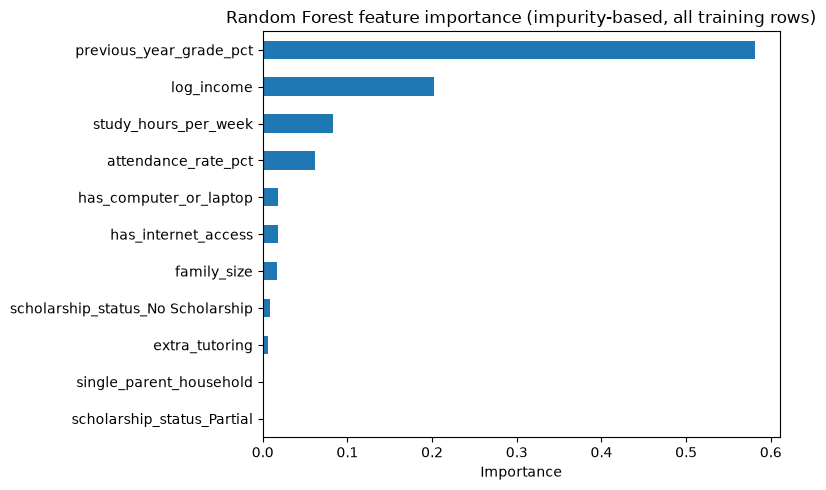

In [34]:
def tune_tree():
    return GridSearchCV(DecisionTreeRegressor(random_state=SEED),
                        {'max_depth': [3, 4, 5, 6, 8, 10], 'min_samples_leaf': [10, 20, 50]},
                        cv=inner_cv, scoring='neg_root_mean_squared_error', n_jobs=-1)


def tune_forest():
    return GridSearchCV(RandomForestRegressor(n_estimators=200, random_state=SEED),
                        {'max_features': [0.33, 0.6, 1.0], 'min_samples_leaf': [5, 20]},
                        cv=inner_cv, scoring='neg_root_mean_squared_error', n_jobs=-1)


tree_results = run_group({
    'Decision Tree': tune_tree,
    'Random Forest': tune_forest,
})

importance = pd.Series(tree_results['fitted']['Random Forest'].feature_importances_, index=MODEL_COLS).sort_values()
importance.plot(kind='barh', figsize=(8, 5))
plt.title('Random Forest feature importance (impurity-based, all training rows)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

### Combined comparison

All six models side by side, with paired tests on outer-fold errors. These tests are exploratory because folds share training observations.

                      cv_rmse  cv_rmse_sd  test_rmse
model                                               
Mean only (baseline)   11.623       0.372     11.834
OLS                     9.669       0.455      9.508
Ridge                   9.669       0.455      9.508
Lasso                   9.669       0.455      9.508
Decision Tree          10.004       0.472      9.931
Random Forest           9.775       0.465      9.663


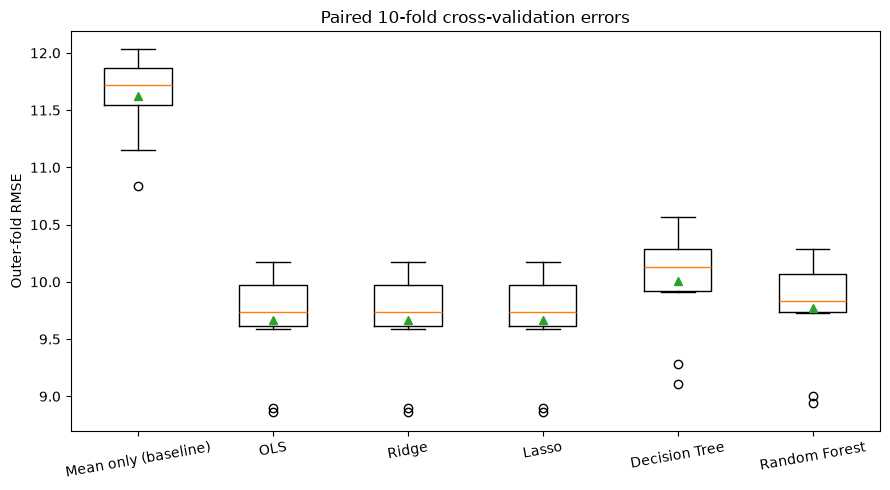

Paired t-test, Mean only (baseline) vs OLS (exploratory): p = 1.956e-10
Paired t-test, OLS vs Ridge (exploratory): p = 0.529
Paired t-test, OLS vs Lasso (exploratory): p = 0.3688
Paired t-test, OLS vs Decision Tree (exploratory): p = 7.46e-07
Paired t-test, OLS vs Random Forest (exploratory): p = 8.646e-07


In [35]:
table_all = pd.concat([baseline_results['table'], linear_results['table'], tree_results['table']])
cv_fold_rmse = {**baseline_results['cv_fold_rmse'], **linear_results['cv_fold_rmse'], **tree_results['cv_fold_rmse']}
print(table_all.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([cv_fold_rmse[name] for name in table_all.index], showmeans=True)
ax.set_xticks(range(1, len(table_all) + 1), table_all.index, rotation=10)
ax.set_ylabel('Outer-fold RMSE')
ax.set_title('Paired 10-fold cross-validation errors')
plt.tight_layout()
plt.show()

for left, right in [
    ('Mean only (baseline)', 'OLS'),
    ('OLS', 'Ridge'),
    ('OLS', 'Lasso'),
    ('OLS', 'Decision Tree'),
    ('OLS', 'Random Forest'),
]:
    p_value = ttest_rel(cv_fold_rmse[left], cv_fold_rmse[right]).pvalue
    print(f'Paired t-test, {left} vs {right} (exploratory): p = {p_value:.4g}')

## Conclusion

On the Lasso-selected predictors, the linear models are the strongest. Every model clearly beats the mean-only baseline, but the tree-based models are noticeably worse than OLS, Ridge and Lasso.

- **Predictors help.** The mean-only baseline has CV RMSE 11.62, versus about 9.67 for OLS, Ridge and Lasso (roughly a 17% reduction). The paired t-test gives p ≈ 2e-10.
- **Linear models are tied.** OLS, Ridge and Lasso all have CV RMSE 9.669 with a fold-to-fold SD of about 0.46. Pairwise p-values are 0.37 to 0.55. The CV-selected Ridge penalty (alpha about 6.3) barely changes the coefficients, and the Lasso penalty sits at the smallest value on the grid (0.0001), so Lasso is effectively OLS here.
- **Trees are worse.** The Random Forest has CV RMSE 9.78 (selected max_features 0.6, min_samples_leaf 20), and the single Decision Tree has 10.00 (max_depth 4, min_samples_leaf 10). Both are significantly worse than OLS (p ≈ 8e-7 for each).
- **Test set agrees.** Refitted on all training rows and scored once on the 1,318-row test set: mean only 11.83, OLS/Ridge/Lasso 9.51, Random Forest 9.66, Decision Tree 9.93.
- **Selection does not improve prediction.** The Lasso step keeps 10 predictors (11 columns). In the nested check, OLS on the selected predictors averages 9.70 RMSE versus 9.60 for OLS on all predictors, and it is better in only 2 of 10 outer folds.

**Interpretation.** Most of the signal looks close to linear and additive (previous-year grade, study hours, attendance and log income dominate). Trees split the data into coarse regions and lose accuracy at this sample size, while the Random Forest's averaging only partly recovers that.

**Caveats.** The paired tests treat folds as independent, but they share training rows, so the p-values are exploratory. The tree and forest grids are small, and the Random Forest uses 200 trees, so these results could shift with a wider search. The Lasso selection was run on the full training set before the comparison, so the comparison CV scores are somewhat optimistic; the nested section is the honest check. Results depend on the random seed.